In [5]:
import numpy as np
import pandas as pd
import sqlite3  # swap for your actual connection (SQLAlchemy engine, etc.)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


conn = sqlite3.connect('../data/finance.db')

In [6]:
pd.read_sql(
    "SELECT interval, source, COUNT(*) AS n, COUNT(DISTINCT ticker) AS tickers, "
    "MIN(datetime) AS first, MAX(datetime) AS last "
    "FROM price_history GROUP BY interval, source",
    conn,
)

,interval,source,n,tickers,first,last
0,15m,yfinance,572,1,2026-09-10 09:30:00-0400,2026-10-09 15:45:00-0400
1,1d,yfinance,2948587,503,2000-01-03,2026-10-08
2,5m,yfinance,1716,1,2026-09-10 09:30:00-0400,2026-10-09 15:55:00-0400


In [7]:
def load_prices(conn, interval="1d", source=None):
    """Load price history for one bar interval from the database.

    Parameters
    ----------
    conn : sqlite3.Connection
        Open connection to the project database.
    interval : str, optional
        Bar interval to select, matching the ``interval`` column.
        Default is ``"1d"``.
    source : str or None, optional
        Data source to select, matching the ``source`` column. If None,
        no source filter is applied, so make sure only one source has
        data for each ticker and date.

    Returns
    -------
    pandas.DataFrame
        Columns ``ticker``, ``date``, ``close``, ``volume``, sorted by
        ticker and date.
    """
    query = (
        "SELECT ticker, datetime, Close AS close, Volume AS volume "
        "FROM price_history WHERE interval = ?"
    )
    params = [interval]
    if source is not None:
        query += " AND source = ?"
        params.append(source)

    df = pd.read_sql(query, conn, params=params)
    dt = pd.to_datetime(df["datetime"], utc=True)
    df["date"] = dt.dt.tz_localize(None).dt.normalize()
    df = df.drop(columns="datetime")

    dupes = df.duplicated(["ticker", "date"]).sum()
    if dupes:
        raise ValueError(f"{dupes} duplicate ticker/date rows; filter by source.")

    return df.sort_values(["ticker", "date"]).reset_index(drop=True)[
        ["ticker", "date", "close", "volume"]
    ]


prices = load_prices(conn, interval="1d", source=None)  # adjust values
prices.head()

,ticker,date,close,volume
0,A,2000-01-03,42.855988,4674353
1,A,2000-01-04,39.582268,4765083
2,A,2000-01-05,37.126972,5758642
3,A,2000-01-06,35.713326,2534434
4,A,2000-01-07,38.689438,2819626


In [8]:
FEATURES = ["ret_1", "ret_5", "ret_20", "vol_20", "ma_ratio", "volume_chg"]


def build_features(prices, horizon=5):
    """Build lagged-return features and a forward-direction target.

    All features use only information available at each row's date.
    The target is whether the close ``horizon`` days ahead is higher
    than today's close.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices``.
    horizon : int, optional
        Number of trading days ahead to predict. Default is 5.

    Returns
    -------
    pandas.DataFrame
        Feature columns, ``target`` (0 or 1), ``ticker`` and ``date``,
        with rows containing NaNs dropped.
    """
    g = prices.groupby("ticker", group_keys=False)
    out = prices.copy()

    daily_ret = g["close"].pct_change()
    out["ret_1"] = daily_ret
    out["ret_5"] = g["close"].pct_change(5)
    out["ret_20"] = g["close"].pct_change(20)
    out["vol_20"] = daily_ret.groupby(out["ticker"]).transform(
        lambda s: s.rolling(20).std()
    )
    ma_50 = g["close"].transform(lambda s: s.rolling(50).mean())
    out["ma_ratio"] = out["close"] / ma_50
    out["volume_chg"] = g["volume"].pct_change(5)

    fwd = g["close"].shift(-horizon) / out["close"] - 1
    out["target"] = (fwd > 0).astype(int)
    out.loc[fwd.isna(), "target"] = np.nan

    out = out.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES + ["target"])
    out["target"] = out["target"].astype(int)
    return out[["ticker", "date", *FEATURES, "target"]]


HORIZON = 5
data = build_features(prices, horizon=HORIZON)
print(data.shape, data["target"].mean())

(2915105, 9) 0.5421417067309754


In [9]:
def walk_forward_scores(data, model, n_splits=5, horizon=5):
    """Evaluate a classifier with expanding-window splits over dates.

    Splitting is done on unique dates (not rows) so every ticker on a
    given day lands in the same fold. A gap of ``horizon`` days between
    train and test prevents the forward-looking target from leaking.

    Parameters
    ----------
    data : pandas.DataFrame
        Output of ``build_features``.
    model : sklearn.base.BaseEstimator
        Unfitted classifier supporting ``predict_proba``.
    n_splits : int, optional
        Number of walk-forward folds. Default is 5.
    horizon : int, optional
        Gap (in trading days) between train and test. Default is 5.

    Returns
    -------
    pandas.DataFrame
        Per-fold accuracy, ROC AUC, and majority-class baseline accuracy.
    """
    dates = np.sort(data["date"].unique())
    fold_edges = np.array_split(dates[len(dates) // 2:], n_splits)
    rows = []
    for i, test_dates in enumerate(fold_edges):
        test_start = test_dates[0]
        train_end_idx = np.searchsorted(dates, test_start) - horizon
        train = data[data["date"].isin(dates[:train_end_idx])]
        test = data[data["date"].isin(test_dates)]

        model.fit(train[FEATURES], train["target"])
        proba = model.predict_proba(test[FEATURES])[:, 1]
        base = max(train["target"].mean(), 1 - train["target"].mean())
        rows.append(
            {
                "fold": i,
                "accuracy": accuracy_score(test["target"], proba > 0.5),
                "auc": roc_auc_score(test["target"], proba),
                "baseline_acc": max(test["target"].mean(), 1 - test["target"].mean()),
            }
        )
    return pd.DataFrame(rows)


models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "rf": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=50, n_jobs=-1, random_state=0
    ),
}

for name, m in models.items():
    res = walk_forward_scores(data, m, horizon=HORIZON)
    print(name)
    print(res.round(3))
    print(res[["accuracy", "auc", "baseline_acc"]].mean().round(3), "\n")

logreg
   fold  accuracy    auc  baseline_acc
0     0     0.547  0.511         0.547
1     1     0.565  0.509         0.566
2     2     0.562  0.507         0.567
3     3     0.527  0.510         0.526
4     4     0.532  0.505         0.534
accuracy        0.547
auc             0.508
baseline_acc    0.548
dtype: float64 

rf
   fold  accuracy    auc  baseline_acc
0     0     0.540  0.505         0.547
1     1     0.552  0.504         0.566
2     2     0.551  0.506         0.567
3     3     0.525  0.505         0.526
4     4     0.526  0.500         0.534
accuracy        0.539
auc             0.504
baseline_acc    0.548
dtype: float64 



In [10]:
def stock_profiles(prices):
    """Summarize each ticker with a few return statistics.

    Parameters
    ----------
    prices : pandas.DataFrame
        Output of ``load_prices`` with columns ``ticker``, ``date``,
        ``close``.

    Returns
    -------
    pandas.DataFrame
        One row per ticker with columns ``avg_return`` (mean daily
        return), ``volatility`` (std of daily returns), and ``beta``
        (how strongly the stock moves with the average stock).
    """
    close = prices.pivot(index="date", columns="ticker", values="close")
    rets = close.pct_change().dropna(how="all")
    market = rets.mean(axis=1)  # the average stock each day

    profiles = pd.DataFrame(
        {
            "avg_return": rets.mean(),
            "volatility": rets.std(),
            "beta": rets.apply(lambda s: s.cov(market) / market.var()),
        }
    )
    return profiles.dropna()


profiles = stock_profiles(prices)
profiles.describe().round(4)

,avg_return,volatility,beta
count,503.0000,503.0000,503.0000
mean,0.0008,0.0234,0.9884
std,0.0007,0.0077,0.3031
min,-0.0026,0.0121,0.2617
25%,0.0005,0.0181,0.7823
50%,0.0007,0.0216,0.9879
75%,0.0009,0.0268,1.1818
max,0.0117,0.0665,2.0600


In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


def cluster_stocks(profiles, n_clusters=4):
    """Group tickers into clusters based on their profile statistics.

    Parameters
    ----------
    profiles : pandas.DataFrame
        Output of ``stock_profiles``.
    n_clusters : int, optional
        Number of groups to find. Default is 4.

    Returns
    -------
    pandas.Series
        Cluster label for each ticker, indexed by ticker.
    """
    scaled = StandardScaler().fit_transform(profiles)  # put columns on equal footing
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
    return pd.Series(km.fit_predict(scaled), index=profiles.index, name="cluster")


profiles["cluster"] = cluster_stocks(profiles, n_clusters=4)
profiles.groupby("cluster").agg(["mean", "count"]).round(4)

avg_return       volatility          beta      
              mean count       mean count    mean count
cluster                                                
0           0.0005   144     0.0170   144  0.6394   144
1           0.0011   116     0.0336   116  1.3399   116
2           0.0007   242     0.0221   242  1.0253   242
3           0.0117     1     0.0665     1  1.5480     1

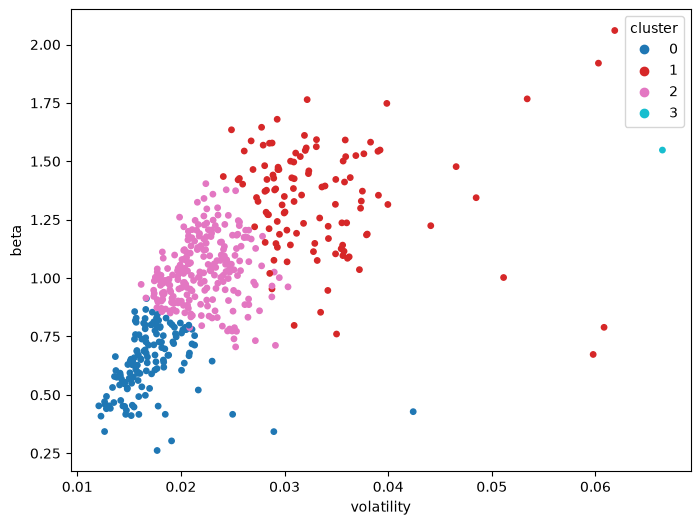

0 ['ABBV', 'ABT', 'ACGL', 'ADM', 'ADP', 'AEE', 'AEP', 'AJG', 'ALLE', 'AMCR']
1 ['AES', 'AIG', 'AKAM', 'ALGN', 'AMAT', 'AMD', 'AMP', 'AMZN', 'ANET', 'APA']
2 ['A', 'AAPL', 'ABNB', 'ACN', 'ADBE', 'ADI', 'ADSK', 'AFL', 'AIZ', 'ALB']
3 ['SNDK']


In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    profiles["volatility"], profiles["beta"], c=profiles["cluster"], cmap="tab10", s=15
)
ax.set_xlabel("volatility")
ax.set_ylabel("beta")
ax.legend(*scatter.legend_elements(), title="cluster")
plt.show()

for c in sorted(profiles["cluster"].unique()):
    print(c, list(profiles[profiles["cluster"] == c].index[:10]))